# Digital-Twin Framework: v0.0.3 Feasibility Study
This notebook implements the v0.0.3 feasibility prototype for the GP27 digital-twin framework. 
It tests whether simulated Medium-Voltage (MV) SCADA measurements and Low-Voltage (LV) switching configurations can distinguish different fault regions before building the full dataset generator.

**Goals:**
1. Establish a healthy pre-fault baseline using the IEEE 33-bus network.
2. Simulate a component failure (Node 10 isolation) and extract post-fault MV measurements.
3. Handle de-energized islands gracefully to prevent solver crashes.
4. Visualize the grid to understand the topological routing.
5. Simulate timestamped, probabilistic customer outage calls based on the physical routing.
6. Build a combined, wide-format feature row that respects a time cutoff to prevent data leakage.
7. Test a hidden LV configuration change to prove robustness.

In [ ]:
# Install required packages if running locally
# !pip install pandapower networkx pandas numpy matplotlib

In [1]:
import pandapower as pp
import pandapower.networks as nw
import pandapower.topology as top
import pandapower.plotting as plot
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

## 1. Network Initialization & Physical Simulation
Load the IEEE 33-bus digital replica, calculate the healthy state, simulate a fault by isolating a node, and extract the resulting SCADA voltage deltas.

In [2]:
# Load the IEEE 33-bus digital replica
net = nw.case33bw()

# Simulate the healthy operating condition
pp.runpp(net)
pre_fault_kv = net.res_bus['vm_pu'] * net.bus['vn_kv']

# Simulate Fault 1: Isolate Node 10
faulted_node = 10
print(f"--- Simulating fault isolation at Node {faulted_node} ---")
net.bus.at[faulted_node, 'in_service'] = False

try:
    # Run post-fault power flow handling de-energized islands 
    pp.runpp(net, check_connectivity=True)
    post_fault_kv = net.res_bus['vm_pu'] * net.bus['vn_kv']
    
    # Build comparison matrix
    comparison_df = pd.DataFrame({
        'Nominal_kV': net.bus['vn_kv'],
        'Pre_Fault_kV': pre_fault_kv,
        'Post_Fault_kV': post_fault_kv,
        'Delta_kV': post_fault_kv - pre_fault_kv,
        'In_Service': net.bus['in_service']
    })
    
    # Explicitly flag de-energized islands (Missing SCADA values)
    comparison_df = comparison_df.fillna('De-energized')
    
    print("\n=== VOLTAGE READINGS (BEFORE VS AFTER) ===")
    display(comparison_df.head(20)) # Display first 20 rows for brevity

except pp.pandapower.api.pandapowerError as e:
    print(f"Power flow failed: {e}")

--- Simulating fault isolation at Node 10 ---

=== VOLTAGE READINGS (BEFORE VS AFTER) ===


,Nominal_kV,Pre_Fault_kV,Post_Fault_kV,Delta_kV,In_Service
0,12.66,12.660000,12.66,0.0,True
1,12.66,12.622428,12.628186,0.005758,True
2,12.66,12.443995,12.480524,0.036529,True
3,12.66,12.349278,12.408539,0.059261,True
4,12.66,12.255630,12.338536,0.082906,True
5,12.66,12.022673,12.16367,0.140998,True
6,12.66,11.978545,12.143377,0.164831,True
7,12.66,11.917218,12.121871,0.204653,True
8,12.66,11.837852,12.109215,0.271363,True
9,12.66,11.764234,12.102816,0.338582,True


## 2. Network Visualization (Topological Map)
Use `networkx` to plot the bus numbers directly to trace which downstream nodes are cut off when Node 10 fails.

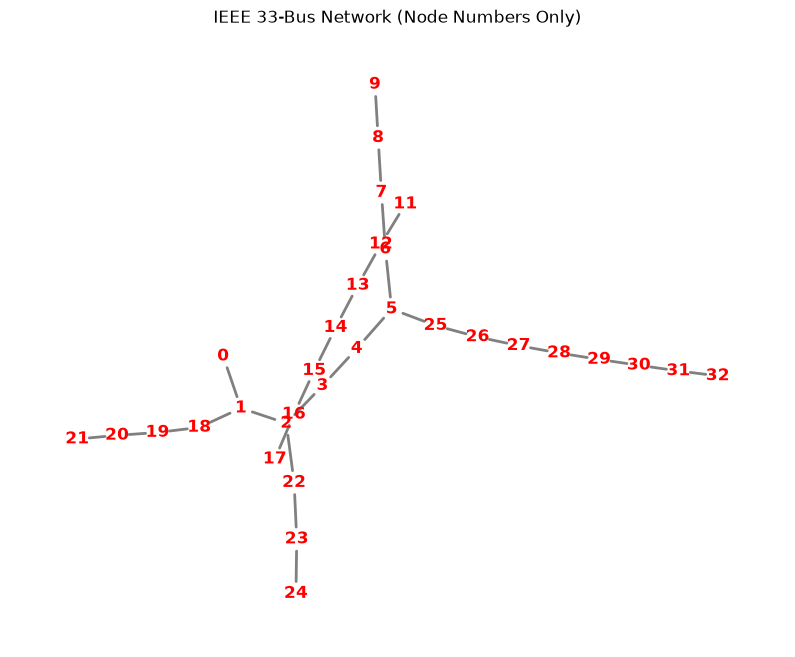

In [8]:
# Create a graph from the pandapower network
mg = top.create_nxgraph(net)

# Calculate a clean layout
pos = nx.kamada_kawai_layout(mg)

plt.figure(figsize=(10, 8))

# Draw edges and labels (no circles)
nx.draw_networkx_edges(mg, pos, edge_color="grey", width=2)
nx.draw_networkx_labels(mg, pos, font_color="red", font_weight="bold", font_size=12)

plt.axis('off')
plt.title("IEEE 33-Bus Network (Node Numbers Only)")
plt.show()

## 3. Customer Call Generation
Assign synthetic customers to nodes. Identify exactly who lost power based on the solver's `De-energized` flags, and simulate a probabilistic reporting process with time delays.

In [4]:
# Assign synthetic customers (10-30 per node)
customer_db = []
for node in range(33):
    num_customers = np.random.randint(10, 31)
    for c in range(num_customers):
        customer_db.append({'customer_id': f'CUST_{node}_{c}', 'customer_area': node})
customer_df = pd.DataFrame(customer_db)

# Identify interrupted customers
outage_nodes = comparison_df[comparison_df['Post_Fault_kV'] == 'De-energized'].index.tolist()
interrupted = customer_df[customer_df['customer_area'].isin(outage_nodes)].copy()

# Apply Bernoulli report probability (40%)
p_report = 0.40  
interrupted['did_call'] = np.random.binomial(1, p_report, len(interrupted))

# Generate incoming calls table with random delays (2 to 45 mins)
calls_table = interrupted[interrupted['did_call'] == 1].copy()
calls_table['call_delay_min'] = np.random.uniform(2, 45, len(calls_table)).round(1)

# Format to match schema
calls_table = calls_table[['customer_id', 'customer_area', 'call_delay_min']].sort_values('call_delay_min').reset_index(drop=True)

print(f"Total Interrupted Customers: {len(interrupted)}")
print(f"Total Calls Simulated: {len(calls_table)}\n")
display(calls_table.head(10))

Total Interrupted Customers: 149
Total Calls Simulated: 58



,customer_id,customer_area,call_delay_min
0,CUST_14_2,14,2.2
1,CUST_13_2,13,2.4
2,CUST_12_13,12,5.6
3,CUST_10_25,10,6.0
4,CUST_15_7,15,6.0
5,CUST_13_4,13,6.4
6,CUST_10_4,10,6.9
7,CUST_10_0,10,7.9
8,CUST_14_5,14,8.9
9,CUST_12_14,12,9.0


## 4. Constructing the Wide Feature Matrix (No Leakage)
Merge the SCADA deltas and the call clusters into a single ML-ready row, strictly enforcing a 15-minute observation cutoff to mimic operational reality.

In [5]:
event_id = "E0001"
cutoff_min = 15  
failed_component = "Node_10"
failure_region = "Branch_10_to_17" 

# Filter Calls by the Cutoff Time
valid_calls = calls_table[calls_table['call_delay_min'] <= cutoff_min]

calls_total = len(valid_calls)
calls_unique_customers = valid_calls['customer_id'].nunique()
calls_area_12 = len(valid_calls[valid_calls['customer_area'] == 12])
calls_area_14 = len(valid_calls[valid_calls['customer_area'] == 14])

# Extract specific SCADA Features (M1 and M5)
m1_pre = comparison_df.at[1, 'Pre_Fault_kV']
m1_post = comparison_df.at[1, 'Post_Fault_kV']
m5_pre = comparison_df.at[9, 'Pre_Fault_kV']
m5_post = comparison_df.at[9, 'Post_Fault_kV']

# Construct single row
feature_dict = {
    'event_id': event_id,
    'cutoff_min': cutoff_min,
    'M1_pre_kV': round(m1_pre, 3),
    'M1_post_kV': round(m1_post, 3),
    'M5_pre_kV': round(m5_pre, 3),
    'M5_post_kV': round(m5_post, 3),
    'calls_total': calls_total,
    'calls_area_12': calls_area_12,
    'calls_area_14': calls_area_14,
    'calls_unique_customers': calls_unique_customers,
    'y_failed_component': failed_component,
    'y_region': failure_region
}

model_features_df = pd.DataFrame([feature_dict])

print(f"=== WIDE MODEL-READY DATASET (CUTOFF: {cutoff_min} MIN) ===")
display(model_features_df)

=== WIDE MODEL-READY DATASET (CUTOFF: 15 MIN) ===


,event_id,cutoff_min,M1_pre_kV,M1_post_kV,M5_pre_kV,M5_post_kV,calls_total,calls_area_12,calls_area_14,calls_unique_customers,y_failed_component,y_region
0,E0001,15,12.622,12.628,11.764,12.103,18,2,4,18,Node_10,Branch_10_to_17


## 5. Robustness Test: Hidden LV Reconfiguration
Simulate a daily grid change where a block of customers is physically switched to a different node, proving the model cannot just memorize the baseline wiring.

In [9]:
# Reset network
net_b = nw.case33bw()
pp.runpp(net_b)
pre_fault_kv_b = net_b.res_bus['vm_pu'] * net_b.bus['vn_kv']

# Apply Hidden Config B: Shift Node 24's customers to Node 25
customer_db_b = []
for node in range(33):
    num_customers = 20
    assigned_node = 25 if node == 24 else node 
    for c in range(num_customers):
        customer_db_b.append({'customer_id': f'CUST_{node}_{c}', 'customer_area': assigned_node})
customer_df_b = pd.DataFrame(customer_db_b)

# Simulate Failure 2: Isolate Node 24
faulted_node_b = 24
net_b.bus.at[faulted_node_b, 'in_service'] = False
pp.runpp(net_b, check_connectivity=True)
post_fault_kv_b = net_b.res_bus['vm_pu'] * net_b.bus['vn_kv']

# Identify Physics-based Outage Nodes
comp_df_b = pd.DataFrame({'Post_Fault_kV': post_fault_kv_b}).fillna('De-energized')
outage_nodes_b = comp_df_b[comp_df_b['Post_Fault_kV'] == 'De-energized'].index.tolist()

# Because of Config B, the Node 24 customers survive (they were on Node 25)
interrupted_b = customer_df_b[customer_df_b['customer_area'].isin(outage_nodes_b)].copy()
interrupted_b['did_call'] = np.random.binomial(1, 0.40, len(interrupted_b))

calls_table_b = interrupted_b[interrupted_b['did_call'] == 1].copy()
calls_table_b['call_delay_min'] = np.random.uniform(2, 45, len(calls_table_b)).round(1)

print(f"--- FAULT AT NODE {faulted_node_b} UNDER LV_Config_B ---")
print(f"Outage Nodes Identified by Physics: {outage_nodes_b}")
print(f"Total Interrupted Customers: {len(interrupted_b)}")
print(f"Total Calls at 15min Cutoff: {len(calls_table_b[calls_table_b['call_delay_min'] <= 15])}")

--- FAULT AT NODE 24 UNDER LV_Config_B ---
Outage Nodes Identified by Physics: [24]
Total Interrupted Customers: 0
Total Calls at 15min Cutoff: 0
